<a href="https://cognitiveclass.ai"><img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DL0101EN-SkillsNetwork/images/IDSN-logo.png" width="400"> </a>

# Transformers with Keras

Estimated time needed **45** mins


In this lab, we will learn how to use the Keras library to build a transformer using a sequence-to-sequence architecture with self-attention for translation. We will train the model using a sample dataset and then use this model for English to Spanish translation.


# Objectives for this Notebook    
* How to use the Keras library to build transformers model
* Train the transformer model using a given dataset
* Use the trained transformer model to translate


<h2>Table of Contents</h2>


<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 4>
1. <a href="#Import-Keras-and-Packages">Import Keras and Packages</a><br>
2. <a href="#Step-1:-Data-Preparation">Step 1: Data Preparation</a><br>
3. <a href="#Step-2:-Self-Attention-Layer">Step 2: Self-Attention Layer</a><br>
4. <a href="#Step-3:-Model-Architecture">Step 3: Model Architecture</a><br>
5. <a href="#Step-4:-Training-the-Model">Step 4: Training the Model</a><br>
6. <a href="#Step-5:-Plotting-the-training-loss">Step 5: Plotting the training loss</a><br>

</font>
</div>


## Import Keras and Packages


Let's start by importing the keras libraries and the packages that we would need to build a neural network.


The following required libraries are __not__ pre-installed in the Skills Network Labs environment. __You will need to run the following cell__ to install them:


In [1]:
# All Libraries required for this lab are listed below. The libraries need to be installed on Skills Network Labs. 
# If you run this notebook on a different environment, e.g. your desktop, you may want to install these.
#!pip install tensorflow_cpu==2.17.1
#!pip install matplotlib==3.9.2

# Installing the libraries, if not installed. Run the following lines to install the required libraries for this lab:
# Terminal>   pip install numpy
# Terminal>   pip install pandas
# Terminal>   pip install tensorflow_cpu
# Terminal>   pip install matplotlib

print("==== All required libraries are installed =====")

==== All required libraries are installed =====


#### Suppress the tensorflow warning messages
We use the following code to  suppress the warning messages due to use of CPU architechture for tensoflow.

You may want to **comment out** these lines if you are using the GPU architechture


In [2]:
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

##### To use Keras, you will also need to install a backend framework – such as TensorFlow.

If you install TensorFlow 2.16 or above, it will install Keras by default.

We are using the CPU version of tensorflow since we are dealing with smaller datasets. 
You may install the GPU version of tensorflow on your machine to accelarate the processing of larger datasets


### Import the necessary libraries


In [3]:
import numpy as np
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import backend as K
from keras.layers import Layer
import warnings  # This line imports the warnings module, which provides a way to control the display
# of warning messages in Python.
warnings.simplefilter('ignore', FutureWarning) # This line sets a filter to ignore FutureWarning messages.
 # FutureWarning is a type of warning that indicates that a feature or behavior in the code
 #  is deprecated and may be removed in future versions of the library. By using this filter, 
 #  any FutureWarning messages will not be displayed during the execution of the code, 
 #  allowing for a cleaner output without warnings about deprecated features.

# Step 1: Data Preparation
We start by define the sentences and text for translation training
Sentence Pairs: Defines a small dataset of English-Spanish sentence pairs.
Target Sequences:
Prepends "startseq" and appends "endseq" to each target sentence for the decoder to learn when to start and stop translating.


In [4]:
# Sample parallel sentences (English -> Spanish)
input_texts = [
    "Hello.", "How are you?", "I am learning machine translation.", "What is your name?", "I love programming."
]
target_texts = [
    "Hola.", "¿Cómo estás?", "Estoy aprendiendo traducción automática.", "¿Cuál es tu nombre?", "Me encanta programar."
]

target_texts = ["startseq " + x + " endseq" for x in target_texts]
 # This line of code modifies the target sentences by adding a start token "startseq" at the beginning
 #  and an end token "endseq" at the end of each sentence in the target_texts list. This is a common 
 #  practice in sequence-to-sequence models, where the start token indicates the beginning of the output
 #  sequence and the end token indicates the end of the output sequence. By adding these tokens, we can
 #  help the model learn when to start and stop generating translations during training and inference.

## Next, we convert the text from the sentences to tokens and create a vocabulary
Tokenization: Uses Tokenizer to convert words into numerical sequences.


In [5]:
## Tokenization
input_tokenizer = Tokenizer()  # This line creates an instance of the Tokenizer class from Keras, which is used
#  to convert text into sequences of integers. The Tokenizer will be fitted on the input_texts to build a 
#  vocabulary and create a mapping of words to integer indices.
input_tokenizer.fit_on_texts(input_texts) # This line fits the Tokenizer on the input_texts, which means it will
#  analyze the text data and create a vocabulary of unique words, assigning a unique integer index to each word
#  based on its frequency in the input_texts. This step is essential for converting the text data into a format 
#  that can be used for training the neural network model.
input_sequences = input_tokenizer.texts_to_sequences(input_texts) # This line converts the input_texts into 
#  sequences of integers using the fitted Tokenizer. Each word in the input_texts is replaced by its 
#  corresponding integer index from the vocabulary created in the previous step. The resulting input_sequences
#  is a list of lists, where each inner list contains the integer indices representing the words in the 
#  corresponding input sentence. This numerical representation of the text data can then be used as input
#  to the neural network model for training. 

output_tokenizer = Tokenizer() # This line creates another instance of the Tokenizer class, which will be used
#  to convert the target_texts into sequences of integers. Similar to the input_tokenizer, this output_tokenizer
#  will be fitted on the target_texts to build a vocabulary and create a mapping of words to integer indices 
#  for the target sentences. 
output_tokenizer.fit_on_texts(target_texts) # This line fits the output_tokenizer on the target_texts, which means
#  it will analyze the target sentences and create a vocabulary of unique words, assigning a unique integer
#  index to each word based on its frequency in the target_texts. This step is crucial for converting the target
#  sentences into a numerical format that can be used for training the neural network model to generate translations.
output_sequences = output_tokenizer.texts_to_sequences(target_texts) # This line converts the target_texts into
#  sequences of integers using the fitted output_tokenizer. Each word in the target_texts is replaced by its 
#  corresponding integer index from the vocabulary created in the previous step. The resulting output_sequences
#  is a list of lists, where each inner list contains the integer indices representing the words in the 
#  corresponding target sentence. This numerical representation of the text data can then be used as target
#  output for training the neural network model. 

input_vocab_size = len(input_tokenizer.word_index) + 1  # This line calculates the size of the input vocabulary
#  by taking the length of the word_index dictionary created by the input_tokenizer and adding 1 to account for
#  the reserved index 0, which is typically
output_vocab_size = len(output_tokenizer.word_index) + 1  # This line calculates the size of the output vocabulary
#  by taking the length of the word_index dictionary created by the output_tokenizer and adding 1 to account for
#  the reserved index 0, which is typically used for padding sequences. The input_vocab_size and output_vocab_size
#  variables will be used later in the model architecture to define the size of the input and output layers,
#  respectively, based on the number of unique words in the input and target sentences.

### Now pad the corresponding sentences
Padding: Ensures all sequences have the same length.


In [6]:
## Padding
max_input_length = max([len(seq) for seq in input_sequences]) # This line calculates the maximum length of 
#  the input sequences by iterating through each sequence in the input_sequences list. For each sequence,
#  it computes its length using len(seq) and keeps track of the maximum length found.
max_output_length = max([len(seq) for seq in output_sequences]) # This line calculates the maximum length of 
#  the output sequences by iterating through each sequence in the output_sequences list. For each sequence,
#  it computes its length using len(seq) and keeps track of the maximum length found. The max_input_length
#  and max_output_length variables will be used to pad the input and output sequences to ensure that they 
#  all have the same length, which is necessary for training the neural network model. 

input_sequences = pad_sequences(input_sequences, maxlen=max_input_length, padding='post') # This line pads
#  the input sequences to ensure that they all have the same length, which is defined by max_input_length. The
#  padding is done by adding zeros at the end of the sequences (padding='post') until they reach the 
#  specified length. This step is crucial for training the neural network model, as it requires input 
#   and output sequences to have the same length for efficient batch processing. 
output_sequences = pad_sequences(output_sequences, maxlen=max_output_length, padding='post') # This line pads
#  the output sequences to ensure that they all have the same length, which is defined by max_output_length.
#  The padding is done by adding zeros at the end of the sequences (padding='post') until they reach the 
#  specified length. This step is crucial for training the neural network model, as it requires input 
#  and output sequences to have the same length for efficient batch processing. 

In [7]:
### Prepare the target data for training:
decoder_input_data = output_sequences[:, :-1] # This line prepares the decoder input data for training by
#  taking all elements of the output_sequences except the last one. This is done because during training,
#  the decoder will be fed the target sequence shifted by one time step, which means that the decoder input
#  will consist of all tokens in the target sequence except the last one (the end token). This allows the 
#  model to learn to predict the next token in the sequence based on the previous tokens, which is
#  essential for training a sequence-to-sequence model for tasks like machine translation. 
decoder_output_data = output_sequences[:, 1:] # This line prepares the decoder output data for training by
#  taking all elements of the output_sequences except the first one. This is done because during training,
#  the decoder will be fed the target sequence shifted by one time step, which means that the decoder output
#  will consist of all tokens in the target sequence except the first one (the start token). This allows the 
#  model to learn to predict the next token in the sequence based on the previous tokens, which is
#  essential for training a sequence-to-sequence model for tasks like machine translation. 

### Convert to one-hot:
decoder_output_data = np.array([np.eye(output_vocab_size)[seq] for seq in decoder_output_data]) # This line
# converts the decoder output data into one-hot encoded format. It uses a list comprehension to iterate 
# through each sequence in decoder_output_data and applies np.eye(output_vocab_size)[seq] to convert each 
# token index in the sequence into a one-hot encoded vector of length output_vocab_size. The resulting 
# decoder_output_data will be a 3D array where each token in the output sequence is represented as a 
# one-hot encoded vector, which is necessary for training the neural network model to predict the correct 
# token at each time step. 

# Step 2: Self-Attention Layer
Self-attention is a mechanism that allows a model to **focus on relevant parts of the input sequence** while processing each word. This is particularly useful in:
1) Machine Translation (e.g., aligning words correctly)
2) Text Summarization
3) Speech Recognition
4) Image Processing (Vision Transformers)
In this implementation, self-attention is used for text based sequence-to-sequence modeling.


Self-Attention works for a given an input sequence by computing a weighted representation of all words for each position. It does so using three key components:

1. Query **(Q)**, Key **(K)**, and Value **(V)** Matrices
For each word (token) in a sequence:

Query (Q): What this word is looking for.
Key (K): What this word represents.
Value (V): The actual information in the word.

2. Compute **Attention Scores**
Next, we **calculate the similarity between each query and key** using dot-product attention:
Each word in a sequence attends to every other word based on these scores.

3. Apply **Scaling & Softmax**
Since dot-product values can be large, we scale them. 
Next, Applying softmax converts scores into attention weights:


### Self-Attention class
In this implementation of self-attention layer:
1. We first initialize the weights in the **build** method, where:
    1. **self.Wq**, **self.Wk**, **self.Wv** are the trainable weight matrices.
    2. Their **shape is (feature_dim, feature_dim)**, meaning they transform input features into Q, K, and V representations.
2. Applying Attention using **call** method. The **call()** method:
   1. Computes **Q, K, V** by multiplying inputs (encoder/decoder output) with their respective weight matrices.
   2. Computes **dot-product attention scores** using K.batch_dot(q, k, axes=[2, 2]), resulting in a (batch_size, seq_len, seq_len) matrix.
   3. **Scales** the scores to avoid large values.
   4. Applies **softmax** to normalize the attention scores.
   5. **Multiplies attention weights with V** to get the final output.
3. The **compute_output_shape** method defines the shape of the output tensor after the layer processes an input.
    1. The output shape of the Self-Attention layer **remains the same** as the input shape.
    2. The attention mechanism **transforms** the input but does not change its dimensions.4
    3. If the attention layer changed the shape, you would modify compute_output_shape


In [ ]:
from tensorflow.keras.layers import Layer # This line imports the Layer class from the tensorflow.keras.layers module,
#  which is a base class for defining custom layers in Keras. By inheriting from this Layer class, 
#  we can create our own custom layer, such as the SelfAttention layer defined below, which can be used
#  in our neural network model for tasks like machine translation. 
from tensorflow.keras import backend as K  # This line imports the backend module from tensorflow.keras, 
#  which provides a way to perform operations on tensors, such as matrix multiplication, dot products,
#  and other mathematical operations that are essential for implementing the self-attention mechanism in
#  the custom SelfAttention layer defined below. 

class SelfAttention(Layer):  # This line defines a new class called SelfAttention that inherits from the
    #  Layer class in Keras. This means that SelfAttention is a custom layer that can be used in a Keras model,
    #  and it will implement the self-attention mechanism, which is a key component in transformer models for
    #  tasks like machine translation. 
    def __init__(self, **kwargs):  # This is the constructor method for the SelfAttention class. It takes
        #  in any number of keyword arguments (**kwargs) that can be passed when creating an instance of
        #  the SelfAttention layer. The constructor calls the constructor of the parent Layer class 
        #  using super(), which allows us to initialize the base Layer class with any additional arguments
        #  that may be needed for the custom layer. This is a common practice when defining custom layers
        #  in Keras to ensure that the base class is properly initialized.
        super(SelfAttention, self).__init__(**kwargs)  # This line calls the constructor of the parent
        #  Layer class using super(), which allows us to initialize the base Layer class with any 
        #  additional arguments that may be needed for the custom SelfAttention layer. This ensures that
        #  the base class is properly initialized.

    def build(self, input_shape):  # This method is called when the layer is being built, and it is 
         # where we define the weights of the layer. 
        ##- input_shape is a list: [q_shape, k_shape, v_shape]
        feature_dim = input_shape[0][-1]  # This line extracts the feature dimension from the input shape.
        #  Since the input_shape is expected to be a list of three shapes for query, key, and value inputs,
        #  we take the first shape (input_shape[0]) which corresponds to the query input, and then we access
        #  the last dimension of that shape ([-1]) to get the feature dimension of the input data. This
        #  feature dimension will be used to define the weights for the query, key, and value transformations
        #  in the self-attention mechanism. 

        self.Wq = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='glorot_uniform',
            trainable=True,
            name='Wq'
        )  # This line defines a weight matrix Wq for the query transformation in the self-attention mechanism.
        #  The add_weight method is used to create a trainable weight variable with the specified shape,
        #  initializer, and name. The shape of Wq is (feature_dim, feature_dim), which means it will be used
        #  to transform the input query vectors into a new space for computing attention scores. The initializer
        #  'glorot_uniform' is commonly used for initializing weights in neural networks, and setting
        #  trainable=True allows the weights to be updated during training. The name 'Wq' is given to this 
        #  weight matrix for identification purposes. 

        self.Wk = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='glorot_uniform',
            trainable=True,
            name='Wk'
        )  # This line defines a weight matrix Wk for the key transformation in the self-attention mechanism.
        #  Similar to Wq, the add_weight method is used to create a trainable weight variable with the specified shape,
        #  initializer, and name. The shape of Wk is also (feature_dim, feature_dim), which means it will be used
        #  to transform the input key vectors into a new space for computing attention scores. The initializer
        #  'glorot_uniform' is used for initializing weights in neural networks, and setting trainable=True allows
        #  the weights to be updated during training. The name 'Wk' is given to this weight matrix for 
        #  identification purposes. 

        self.Wv = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='glorot_uniform',
            trainable=True,
            name='Wv'
        )  # This line defines a weight matrix Wv for the value transformation in the self-attention mechanism.
        #  Similar to Wq and Wk, the add_weight method is used to create a trainable weight variable with the specified shape,
        #  initializer, and name. The shape of Wv is also (feature_dim, feature_dim), which means it will be used
        #  to transform the input value vectors into a new space for computing attention scores. The initializer
        #  'glorot_uniform' is used for initializing weights in neural networks, and setting trainable=True allows
        #  the weights to be updated during training. The name 'Wv' is given to this weight matrix for 
        #  identification purposes. 

        super(SelfAttention, self).build(input_shape) # This line calls the build method of the parent Layer
        #  class using super(), which allows us to complete the build process for the custom SelfAttention layer.
        #  This is necessary to ensure that the base class build method is properly executed, which may
        #  include additional setup or checks required for the layer to function correctly in the Keras framework. 

    def call(self, inputs):  # This method defines the forward pass of the layer, where we implement the self-attention mechanism. 
        ##- Expect list: [query, key, value]
        q, k, v = inputs     # This line unpacks the inputs into query (q), key (k), and value (v) tensors. 
         #   The call method is expected to receive a list of three tensors corresponding to the query, key,
         #   and value inputs for the self-attention mechanism. 

        q = K.dot(q, self.Wq) # This line applies a linear transformation to the query tensor q using the 
          #  weight matrix Wq defined in the build method. 
        k = K.dot(k, self.Wk) # This line applies a linear transformation to the key tensor k using the
          #  weight matrix Wk defined in the build method. 
        v = K.dot(v, self.Wv) # This line applies a linear transformation to the value tensor v using the
          #  weight matrix Wv defined in the build method.

        ##- Scaled dot-product attention
        scores = K.batch_dot(q, k, axes=[2, 2])  # This line computes the attention scores by performing a
          # batch dot product between the transformed query tensor q and the transformed key tensor k.
          # The axes parameter specifies that the dot product should be computed along the last dimension
          # of both tensors (the feature dimension). The resulting scores tensor will have a shape that 
          # allows us to compute the attention weights for each query-key pair. 
        dk = K.cast(K.shape(k)[-1], dtype=K.floatx()) # This line calculates the scaling factor dk, which
          # is the dimension of the key vectors. It takes the shape of the transformed key tensor k, 
          # accesses the last dimension (which corresponds to the feature dimension), and casts it to the appropriate floating-point type using K.floatx().
        scores = scores / K.sqrt(dk)

        attention_weights = K.softmax(scores, axis=-1)
        output = K.batch_dot(attention_weights, v)

        return output


# Step 3: Model Architecture
The model follows an Encoder-Decoder structure:

### Encoder:
1) Takes input sentences (padded and tokenized).
2) Uses an Embedding layer (word representations) + LSTM (to process sequences).
    1. The LSTMs are used as the **help process variable-length input sentences** and generate meaningful translations.
4) Outputs context vectors (hidden & cell states).

### Attention Layer
1) Applied to both the encoder and decoder outputs.
2) Helps the decoder focus on relevant words during translation.

### Decoder
1) Receives target sequences (shifted one step ahead).
2) Uses an LSTM with encoder states as initial states.
3) Applies self-attention for better learning.
4) Uses a Dense layer (Softmax) to predict the next word.


In [9]:
from tensorflow.keras.layers import AdditiveAttention, Concatenate, Dense, Embedding, Input, LSTM
from tensorflow.keras.models import Model
 
# Encoder
encoder_inputs = Input(shape=(max_input_length,))
encoder_embedding = Embedding(input_vocab_size, 256)(encoder_inputs)
encoder_lstm = LSTM(256, return_sequences=True, return_state=True)
encoder_outputs, state_h, state_c = encoder_lstm(encoder_embedding)
encoder_states = [state_h, state_c]
 
# Decoder
decoder_inputs = Input(shape=(max_output_length - 1,))
decoder_embedding = Embedding(output_vocab_size, 256)(decoder_inputs)
decoder_lstm = LSTM(256, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_embedding, initial_state=encoder_states)
 
# Attention: decoder attends to encoder outputs
self_attention = SelfAttention()
attention_output = self_attention(
    [decoder_outputs, encoder_outputs, encoder_outputs]
)

 
# Combine decoder outputs with attention context
decoder_concat = Concatenate(axis=-1)([decoder_outputs, attention_output])
 
# Final Dense layer
decoder_dense = Dense(output_vocab_size, activation='softmax')
decoder_outputs = decoder_dense(decoder_concat)
 
# Full Model
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
 
# Summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 5, 256)    │      4,096 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 5, 256)    │      4,352 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 5, 256),  │    525,312 │ embedding[0][0]   │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 5, 256),  │    525,312 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ lstm[0][1],       │
│                     │ (None, 256)]      │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention      │ (None, 5, 256)    │    196,608 │ lstm_1[0][0],     │
│ (SelfAttention)     │                   │            │ lstm[0][0],       │
│                     │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 5, 512)    │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ self_attention[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 5, 17)     │      8,721 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,264,401 (4.82 MB)

 Trainable params: 1,264,401 (4.82 MB)

 Non-trainable params: 0 (0.00 B)

# Step 4: Training the Model
Uses categorical_crossentropy as the loss function since output words are one-hot encoded.
Trains using Adam optimizer for 100 epochs.


In [10]:
# Step 6: Train the Model
history_glorot_adam = model.fit([input_sequences, decoder_input_data], decoder_output_data, epochs=100, batch_size=16)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - accuracy: 0.0400 - loss: 2.8326
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.3600 - loss: 2.7964
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.3200 - loss: 2.7572
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.3200 - loss: 2.7101
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.3200 - loss: 2.6504
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.3200 - loss: 2.5724
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.2800 - loss: 2.4710
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.2800 - loss: 2.3451
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.2800 - loss: 2.2106
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.2400 - loss: 2.1184
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.2400 - loss: 2.1020
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.

# Step 5: Plotting the training loss


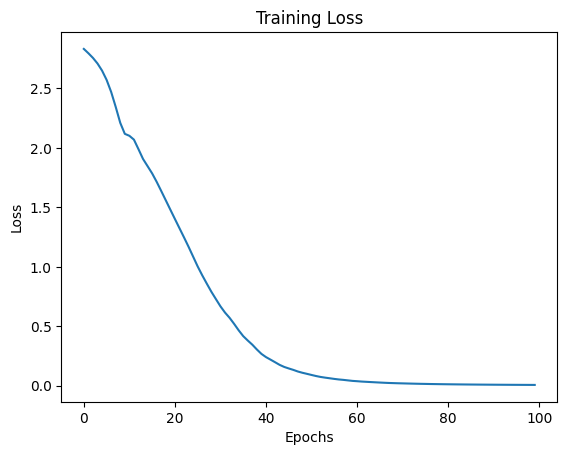

In [11]:
##- Plotting training loss
import matplotlib.pyplot as plt
plt.plot(history_glorot_adam.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

# Awesome, now you have succesfully trained a transformers model.
### Now let's try some practice excercises


## Practice excercise 1


In this practice exercise, let's train the model using "he_uniform" initializer instead of "glorot_uniform". Then, compare the training loss between model using "glorot_uniform" vs "he_uniform" initializers by plotting them using matplotlib


Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.0800 - loss: 2.8307
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.3200 - loss: 2.7907
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.3200 - loss: 2.7472
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.3200 - loss: 2.6952
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.3200 - loss: 2.6298
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.3200 - loss: 2.5459
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.2800 - loss: 2.4395
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.2800 - loss: 2.3148
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.2800 - loss: 2.2019
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.2800 - loss: 2.1577
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.2800 - loss: 2.1396
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.3200 - 

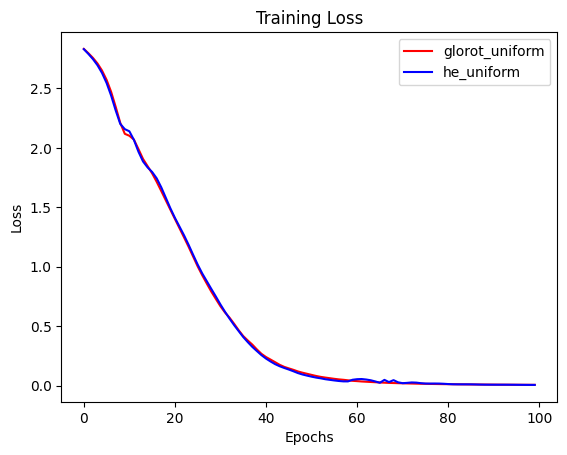

In [12]:
## Write your answer here - Practice excercise 1

#Define the Self-Attention Layer
from tensorflow.keras.layers import Layer
from tensorflow.keras import backend as K

class SelfAttention(Layer):
    def __init__(self, **kwargs):
        super(SelfAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        # input_shape is a list: [q_shape, k_shape, v_shape]
        feature_dim = input_shape[0][-1]

        self.Wq = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='he_uniform',
            trainable=True,
            name='Wq'
        )

        self.Wk = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='he_uniform',
            trainable=True,
            name='Wk'
        )

        self.Wv = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='he_uniform',
            trainable=True,
            name='Wv'
        )

        super(SelfAttention, self).build(input_shape)

    def call(self, inputs):
        # Expect list: [query, key, value]
        q, k, v = inputs

        q = K.dot(q, self.Wq)
        k = K.dot(k, self.Wk)
        v = K.dot(v, self.Wv)

        # Scaled dot-product attention
        scores = K.batch_dot(q, k, axes=[2, 2])
        dk = K.cast(K.shape(k)[-1], dtype=K.floatx())
        scores = scores / K.sqrt(dk)

        attention_weights = K.softmax(scores, axis=-1)
        output = K.batch_dot(attention_weights, v)

        return output


from tensorflow.keras.layers import AdditiveAttention, Concatenate, Dense, Embedding, Input, LSTM
from tensorflow.keras.models import Model
 
# Encoder
encoder_inputs = Input(shape=(max_input_length,))
encoder_embedding = Embedding(input_vocab_size, 256)(encoder_inputs)
encoder_lstm = LSTM(256, return_sequences=True, return_state=True)
encoder_outputs, state_h, state_c = encoder_lstm(encoder_embedding)
encoder_states = [state_h, state_c]
 
# Decoder
decoder_inputs = Input(shape=(max_output_length - 1,))
decoder_embedding = Embedding(output_vocab_size, 256)(decoder_inputs)
decoder_lstm = LSTM(256, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_embedding, initial_state=encoder_states)
 
# Attention: decoder attends to encoder outputs
self_attention = SelfAttention()
attention_output = self_attention(
    [decoder_outputs, encoder_outputs, encoder_outputs]
)

 
# Combine decoder outputs with attention context
decoder_concat = Concatenate(axis=-1)([decoder_outputs, attention_output])
 
# Final Dense layer
decoder_dense = Dense(output_vocab_size, activation='softmax')
decoder_outputs = decoder_dense(decoder_concat)
 
# Full Model
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
 
# Summary
#Step 6: Train the Model
history_he = model.fit([input_sequences, decoder_input_data], decoder_output_data, epochs=100, batch_size=16)

#Plotting training losses for glorot_uniform and he_uniform inititalizers
import matplotlib.pyplot as plt
plt.plot(history_glorot_adam.history['loss'], label="glorot_uniform", color='red')
plt.plot(history_he.history['loss'], label="he_uniform", color='blue')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Double-click <b>here</b> for the solution.

<!-- Your answer is below:


#Define the Self-Attention Layer
from tensorflow.keras.layers import Layer
from tensorflow.keras import backend as K

class SelfAttention(Layer):
    def __init__(self, **kwargs):
        super(SelfAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        # input_shape is a list: [q_shape, k_shape, v_shape]
        feature_dim = input_shape[0][-1]

        self.Wq = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='he_uniform',
            trainable=True,
            name='Wq'
        )

        self.Wk = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='he_uniform',
            trainable=True,
            name='Wk'
        )

        self.Wv = self.add_weight(
            shape=(feature_dim, feature_dim),
            initializer='he_uniform',
            trainable=True,
            name='Wv'
        )

        super(SelfAttention, self).build(input_shape)

    def call(self, inputs):
        # Expect list: [query, key, value]
        q, k, v = inputs

        q = K.dot(q, self.Wq)
        k = K.dot(k, self.Wk)
        v = K.dot(v, self.Wv)

        # Scaled dot-product attention
        scores = K.batch_dot(q, k, axes=[2, 2])
        dk = K.cast(K.shape(k)[-1], dtype=K.floatx())
        scores = scores / K.sqrt(dk)

        attention_weights = K.softmax(scores, axis=-1)
        output = K.batch_dot(attention_weights, v)

        return output


from tensorflow.keras.layers import AdditiveAttention, Concatenate, Dense, Embedding, Input, LSTM
from tensorflow.keras.models import Model
 
# Encoder
encoder_inputs = Input(shape=(max_input_length,))
encoder_embedding = Embedding(input_vocab_size, 256)(encoder_inputs)
encoder_lstm = LSTM(256, return_sequences=True, return_state=True)
encoder_outputs, state_h, state_c = encoder_lstm(encoder_embedding)
encoder_states = [state_h, state_c]
 
# Decoder
decoder_inputs = Input(shape=(max_output_length - 1,))
decoder_embedding = Embedding(output_vocab_size, 256)(decoder_inputs)
decoder_lstm = LSTM(256, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_embedding, initial_state=encoder_states)
 
# Attention: decoder attends to encoder outputs
self_attention = SelfAttention()
attention_output = self_attention(
    [decoder_outputs, encoder_outputs, encoder_outputs]
)

 
# Combine decoder outputs with attention context
decoder_concat = Concatenate(axis=-1)([decoder_outputs, attention_output])
 
# Final Dense layer
decoder_dense = Dense(output_vocab_size, activation='softmax')
decoder_outputs = decoder_dense(decoder_concat)
 
# Full Model
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
 
# Summary
#Step 6: Train the Model
history_he = model.fit([input_sequences, decoder_input_data], decoder_output_data, epochs=100, batch_size=16)

#Plotting training losses for glorot_uniform and he_uniform inititalizers
import matplotlib.pyplot as plt
plt.plot(history_glorot_adam.history['loss'], label="glorot_uniform", color='red')
plt.plot(history_he.history['loss'], label="he_uniform", color='blue')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


-->


## Practice excercise 2


In this practice exercise, try to use adaptive gradient optimizer instead of adam. Then, plot and compare the results between adam and adaptive gradient optimizers


Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 1.0000 - loss: 0.0059
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 1.0000 - loss: 0.0059
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 1.0000 - loss: 0.0058
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 1.0000 -

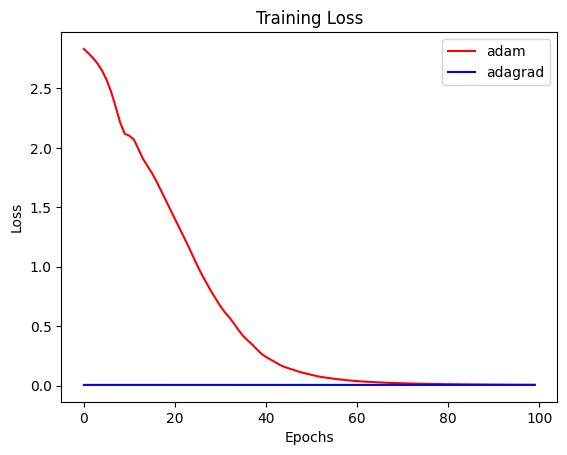

In [13]:
### Write your answer here - Practice excercise 2

##----- Full Model
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer='adagrad', loss='categorical_crossentropy', metrics=['accuracy'])


#Step 6: Train the Model
history_adagrad = model.fit([input_sequences, decoder_input_data], decoder_output_data, epochs=100, batch_size=16)

#Plotting training losses for glorot_uniform and he_uniform inititalizers
import matplotlib.pyplot as plt
plt.plot(history_glorot_adam.history['loss'], label="adam", color='red')
plt.plot(history_adagrad.history['loss'], label="adagrad", color='blue')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Double-click <b>here</b> for the solution.

<!-- Your answer is below:

#Full Model
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer='adagrad', loss='categorical_crossentropy', metrics=['accuracy'])


#Step 6: Train the Model
history_adagrad = model.fit([input_sequences, decoder_input_data], decoder_output_data, epochs=100, batch_size=16)

#Plotting training losses for glorot_uniform and he_uniform inititalizers
import matplotlib.pyplot as plt
plt.plot(history_glorot_adam.history['loss'], label="adam", color='red')
plt.plot(history_adagrad.history['loss'], label="adagrad", color='blue')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
-->


## Thank you for completing this lab!

This notebook was created by [Aman Aggarwal](https://www.linkedin.com/in/aggarwal-aman/). I hope you found this lab interesting and educational. Feel free to contact me if you have any questions!


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2024-11-20  | 1.0  | Aman  |  Created the lab |
<hr>
-->
## <h3 align="center"> © IBM Corporation. All rights reserved. <h3/>
